# 3. Life cycles: the deterministic limit

The thesis model has no noise: an immigration floor keeps every firm alive,

$$\dot x_i=x_i\Big[1-\frac{x_i}{m}+\frac1m\sum_jJ_{ij}x_j\Big]+\lambda\,(m-x_i),\qquad
\frac{d\ln S_i}{dt}=\Phi_i(t)-S_i+\lambda\big(S_i^{-1}-1\big),\qquad \Phi_i=1-\bar f(t)+(JS)_i .$$

Here a firm's life is a **spell**: a maximal stretch above a listing threshold $S_{\rm thr}=8\lambda$ (the share
$10^{-6}$ at $\lambda=10^{-3}$, $N=8000$). This notebook solves the one-firm problem exactly, derives when a firm
exits and how long it lives, and shows why this limit alone cannot match the data, which motivates the
demographic model of notebooks 04–06. Production values: $N=8000$, $C=200$, $\lambda=10^{-3}$, $\mu=-1.76$,
$\alpha\in\{2.5,3.5,6\}$.

**Size is mean fitness (exact).** Averaging the one-firm equation over a window in which $\ln S_i$ starts and ends
at the same value, $\bar S_i=\bar\Phi_i+\lambda(\overline{S_i^{-1}}-1)\simeq\bar\Phi_i$. A firm is large because its
environment is favourable on average; its size is a running estimate of that environment.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis
from scipy.optimize import curve_fit, brentq
from joblib import Parallel, delayed
from economy import powerlaw_coupling, DATA, tidy

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})
POINTS = (("6.0", "1.75"), ("3.5", "1.9"), ("2.5", "1.75"))
DT, DTI, START, T = 0.5, 0.02, 180.0, 480.0

**Simulation and measurement.** The full model is integrated in shares $w_i=x_i/M$ on the simplex, which never overflows
although $M$ grows exponentially. A spell is a maximal stretch above the listing floor on the yearly grid; each counts as one
firm with its mean size and $\sqrt{\pi/2}\,$MAD volatility. $\beta$ is fitted from the peak of the binned median volatility
rightward (the thesis estimator), $\zeta_q$ on the same decline branch. Per point the full model's fitness
$\Phi_i(t)=1-\bar f(t)-(JS)_i$ and its spell statistics are cached in `data/lifecycle/fit_*.npz` (eight economies, $N=8000$,
window $[180,660]$; about 10 minutes per point to regenerate).

In [2]:
def integrate_deterministic(a, *, tmax, n_eval, lam, seed):
    """dw_i/dt = w_i (f_i - <f>) + lam (1/N - w_i),  f_i = 1 - N w_i - N (a w)_i,  <f> = sum_i w_i f_i."""
    from scipy.integrate import solve_ivp
    n = a.shape[0]
    w0 = np.random.default_rng(seed).uniform(0.5, 1.5, n)
    def rhs(t, w):
        w = np.clip(w, 0.0, None)
        w = w / w.sum()
        f = 1.0 - n * w - n * (a @ w)
        return w * (f - w @ f) + lam * (1.0 / n - w)
    r = solve_ivp(rhs, (0.0, tmax), w0 / w0.sum(), method="RK45", t_eval=np.linspace(0.0, tmax, n_eval), rtol=1e-4, atol=1e-7)
    W = np.clip(r.y, 0.0, None)
    return r.t, W / W.sum(0, keepdims=True)


def decline_beta(Sb, v, nb=20):
    """sigma(S) ~ S^-beta from the peak bin of the median volatility rightward."""
    o = np.argsort(Sb)
    P = np.array_split(o, nb)
    bx, by = np.array([Sb[p].mean() for p in P]), np.array([np.median(v[p]) for p in P])
    pk = int(np.argmax(by))
    return -np.polyfit(np.log10(bx[pk:]), np.log10(by[pk:]), 1)[0]


def decline_zeta(Sb, v, nb=20):
    """zeta_1..4 on the decline branch of one economy (from the peak bin of the median volatility rightward)."""
    ok = (v > 0) & (Sb > 0)
    Sb, v = Sb[ok], v[ok]
    o = np.argsort(Sb)
    P = np.array_split(np.arange(o.size), nb)
    bx, by = np.array([Sb[o][p].mean() for p in P]), np.array([np.median(v[o][p]) for p in P])
    pk = int(np.argmax(by))
    dec = Sb > bx[pk]
    Sx, vx = Sb[dec], v[dec]
    ox = np.argsort(Sx)
    Px = np.array_split(np.arange(ox.size), max(6, nb - pk))
    lx = np.log([Sx[ox][p].mean() for p in Px])
    return np.array([-np.polyfit(lx, np.log([np.mean(vx[ox][p] ** q) for p in Px]), 1)[0] for q in (1, 2, 3, 4)])


def spell_volatility(W, t, *, window, dt, floor, min_growth=2):
    """MSB unbalanced panel on shares W: every stretch above `floor` with >= min_growth growth rates is one firm."""
    n = W.shape[0]
    tg = np.arange(window[0], window[1] + 1e-9, dt)
    lnS = np.array([np.interp(tg, t, np.log(np.maximum(n * w, 1e-300))) for w in W])
    on = np.pad(lnS > np.log(n * floor), ((0, 0), (1, 1)))
    i, j = np.nonzero(np.diff(on.astype(np.int8), axis=1))    # alternating start / end per firm
    a, b = j[::2], j[1::2]
    keep = b - a > min_growth
    Sbar, vol = [], []
    for f, s_, e in zip(i[::2][keep], a[keep], b[keep]):
        g = np.diff(lnS[f, s_:e])
        Sbar.append(np.exp(lnS[f, s_:e]).mean())
        vol.append(np.sqrt(np.pi / 2) * np.abs(g - g.mean()).mean())
    Sbar, vol = np.array(Sbar), np.array(vol)
    ok = vol > 0
    return dict(Sbar=Sbar, vol=vol, beta=decline_beta(Sbar[ok], vol[ok]))


def fitness_stats(alpha, sigma, lam=1e-3, n=8000, seeds=8):
    """Per firm: window-mean fitness m, its temporal sd f, degree k; mean ACF of the fluctuation; spell beta and zeta."""
    path = DATA / "lifecycle" / f"fit_a{alpha}_s{sigma}_l{lam:.0e}.npz"
    if not path.exists():
        def economy(seed):
            a = powerlaw_coupling(n, 1.76, float(sigma), alpha=float(alpha), mean_degree=n // 40, seed=seed)
            t, W = integrate_deterministic(a, tmax=START + T, n_eval=int((START + T) / DT) + 1, lam=lam, seed=seed)
            win = t >= START - 1e-9
            S = n * W[:, win]
            AS = np.asarray(a @ S)
            Phi = 1 - (W[:, win] * (1 - S - AS)).sum(0)[None, :] - AS
            m, f = Phi.mean(1), Phi.std(1)
            d = (Phi - m[:, None]) / np.maximum(f[:, None], 1e-12)
            acf = np.array([np.mean(d[:, :d.shape[1] - L] * d[:, L:]) for L in range(61)])
            sp = spell_volatility(W, t, window=(START, START + T), dt=DT, floor=8 * lam / n)
            return m, f, np.diff(a.indptr), acf, sp["beta"], decline_zeta(sp["Sbar"], sp["vol"])
        R = Parallel(n_jobs=seeds)(delayed(economy)(s) for s in range(seeds))
        np.savez(path, m=np.concatenate([r[0] for r in R]), f=np.concatenate([r[1] for r in R]),
                 k=np.concatenate([r[2] for r in R]), acf=np.mean([r[3] for r in R], 0),
                 beta=np.array([r[4] for r in R]), Z=np.array([r[5] for r in R]))
    return np.load(path)


fits = {p: fitness_stats(*p) for p in POINTS}

## The fitness law

For the bilinear kernel the HDMFT field on a firm of relative degree $\kappa$ is
$\Phi(t)=1-\bar f+\mu\kappa\bar B+\sigma\sqrt\kappa\,\xi(t)$ with $\mathbb E[\xi(t)\xi(t')]=Q(t-t')$ (notebook 02). Over a window of
length $T$, split $Q$ into the part that is static over the window, $Q_T=\sum_jw_j\bar S_j^2$ (degree-weighted, it does not
vanish as $T\to\infty$: quenched couplings turn the neighbours' positive mean sizes into a static random field), and
the rest. At zero reciprocity the fitness is $\Phi=\bar\Phi+f_\kappa\eta(t)$, $\eta$ of unit variance, with

$$\bar\Phi\mid\kappa\sim\mathcal N\big(r_\kappa,\,a_\kappa^2\big),\quad r_\kappa=1-\bar f+\mu\kappa\bar B,\quad a_\kappa=\sigma\sqrt{\kappa Q_T},\quad
f_\kappa=\sigma\sqrt{\kappa(Q_0-Q_T)},\quad \rho(L)\simeq\frac{Q(L)-Q_T}{Q_0-Q_T}.$$

Four order parameters ($\bar f$, $\bar B$, $Q_T$, $Q_0$) and a correlation time fix the fitness of every firm.
Consequences: **degree heterogeneity is amplitude heterogeneity** ($a_\kappa,f_\kappa\propto\sqrt\kappa$); under competition
the mean falls linearly in $\kappa$ while the spread grows as $\sqrt\kappa$, so on a Pareto degree law the mixture skews
$\bar\Phi$ to the left; hubs are rarely large.

The stored fitness of the full model (`data/lifecycle/fit_*.npz`: per firm the window mean $\bar\Phi_i$, the
fluctuation amplitude $f_i$ and the degree, eight economies per point, window $[180,660]$) tests the shape of the law.
The order parameters differ between economies, so in each economy they are read off its degree classes (mean linear in
$\kappa$, variance and $f^2$ proportional to $\kappa$); what is tested is that this is all there is: a Gaussian at fixed
degree, and the left skew of the mixture over degrees.

alpha 6.0, sigma 1.75: z = (Phibar - r)/a: mean -0.002 sd 0.996 skew -0.01 exkurt +0.23;  skew of Phibar -0.11 (law -0.10);  f / f_kappa median 0.96
alpha 3.5, sigma 1.9: z = (Phibar - r)/a: mean -0.000 sd 0.961 skew -0.02 exkurt +0.28;  skew of Phibar -0.87 (law -1.10);  f / f_kappa median 0.97


alpha 2.5, sigma 1.75: z = (Phibar - r)/a: mean -0.001 sd 0.731 skew -0.03 exkurt +0.61;  skew of Phibar -4.56 (law -3.57);  f / f_kappa median 0.96


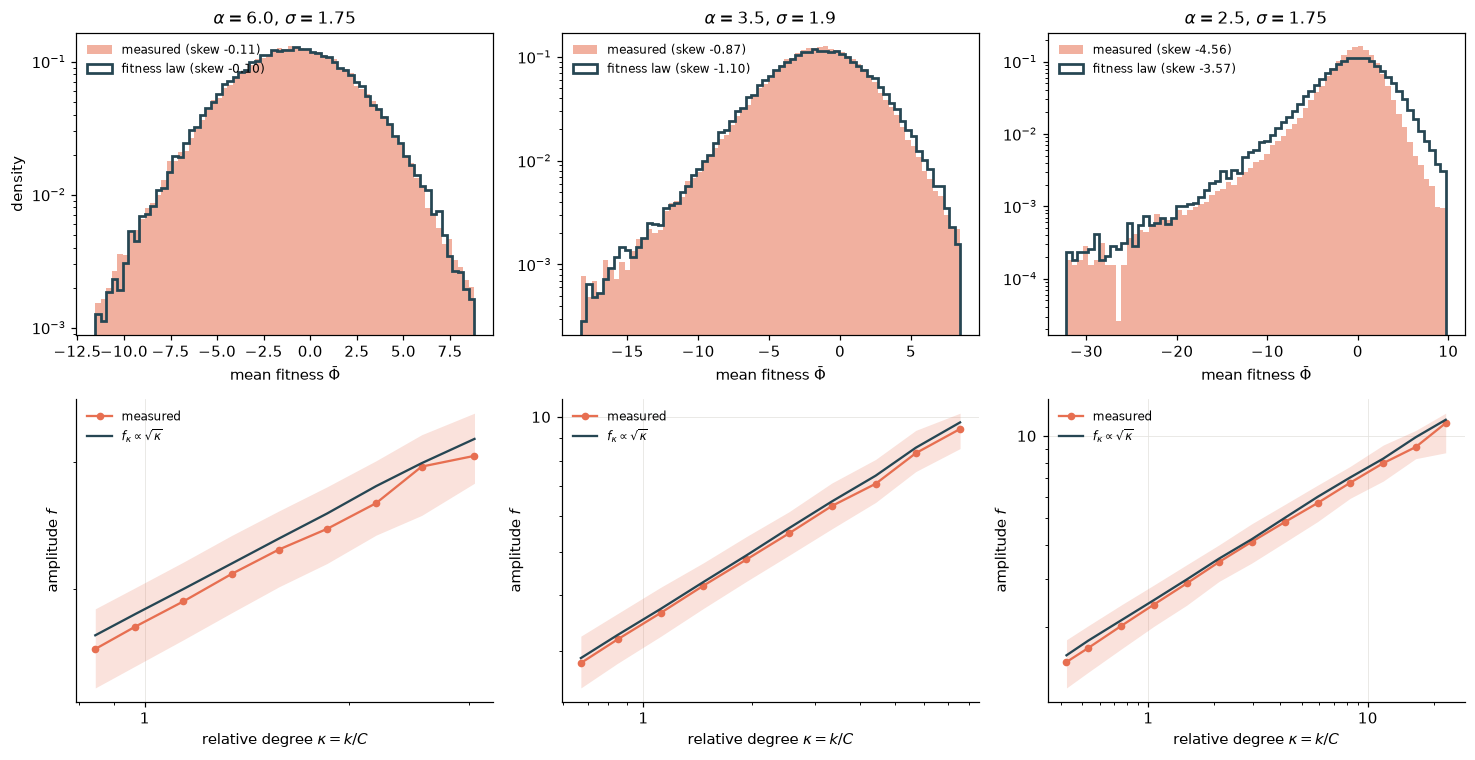

In [3]:
def law_one(m, f, k, n_bins=20):
    """Order parameters of one economy read off its degree classes: r_kappa = c0 + c1 kappa, a_kappa^2 and f_kappa^2 ~ kappa."""
    kap = k / k.mean()
    e = np.quantile(kap, np.linspace(0, 1, n_bins + 1))
    b = np.clip(np.digitize(kap, e[1:-1]), 0, n_bins - 1)
    J = [j for j in range(n_bins) if (b == j).sum() > 20]          # degree ties leave some classes empty
    kc = np.array([kap[b == j].mean() for j in J])
    c = np.polyfit(kc, [m[b == j].mean() for j in J], 1)
    a2 = np.sum(np.array([m[b == j].var() for j in J]) * kc) / np.sum(kc * kc)
    F2 = np.sum(np.array([np.mean(f[b == j] ** 2) for j in J]) * kc) / np.sum(kc * kc)
    return kap, np.polyval(c, kap), np.sqrt(a2 * kap), np.sqrt(F2 * kap)


def law(fit, n=8000):
    """The law fitted economy by economy (each has its own order parameters), pooled."""
    parts = [law_one(*(fit[x][e * n:(e + 1) * n].astype(float) for x in ("m", "f", "k"))) for e in range(fit["m"].size // n)]
    kap, r, a, fk = (np.concatenate(x) for x in zip(*parts))
    return dict(kap=kap, r=r, a=a, fk=fk, z=(fit["m"] - r) / a)


fig, ax = plt.subplots(2, 3, figsize=(13.5, 7))
rng = np.random.default_rng(1)
for j, p in enumerate(POINTS):
    fit, L = fits[p], law(fits[p])
    m, f = fit["m"], fit["f"]
    sample = L["r"] + L["a"] * rng.standard_normal(m.size)
    print(f"alpha {p[0]}, sigma {p[1]}: z = (Phibar - r)/a: mean {L['z'].mean():+.3f} sd {L['z'].std():.3f} "
          f"skew {skew(L['z']):+.2f} exkurt {kurtosis(L['z']):+.2f};  skew of Phibar {skew(m):+.2f} (law {skew(sample):+.2f});"
          f"  f / f_kappa median {np.median(f / L['fk']):.2f}")
    bins = np.linspace(np.percentile(m, 0.2), np.percentile(m, 99.8), 70)
    ax[0, j].hist(m, bins, density=True, color="#e76f51", alpha=0.55, label=f"measured (skew {skew(m):.2f})")
    ax[0, j].hist(sample, bins, density=True, histtype="step", color="#264653", lw=1.8, label=f"fitness law (skew {skew(sample):.2f})")
    ax[0, j].set(yscale="log", xlabel=r"mean fitness $\bar\Phi$", title=rf"$\alpha={p[0]}$, $\sigma={p[1]}$")
    ax[0, j].legend(fontsize=8, frameon=False)
    kap = L["kap"]
    e = np.geomspace(kap.min(), kap.max() * 1.0001, 16)
    idx = np.clip(np.digitize(kap, e) - 1, 0, len(e) - 2)
    keep = [i for i in range(len(e) - 1) if (idx == i).sum() >= 50]
    kc = np.array([np.median(kap[idx == i]) for i in keep])
    ax[1, j].plot(kc, [np.median(f[idx == i]) for i in keep], "o-", color="#e76f51", ms=4, label="measured")
    ax[1, j].fill_between(kc, [np.quantile(f[idx == i], 0.25) for i in keep], [np.quantile(f[idx == i], 0.75) for i in keep],
                          color="#e76f51", alpha=0.2, lw=0)
    ax[1, j].plot(kc, [np.median(L["fk"][idx == i]) for i in keep], color="#264653", label=r"$f_\kappa\propto\sqrt{\kappa}$")
    ax[1, j].set(xscale="log", yscale="log", xlabel=r"relative degree $\kappa=k/C$", ylabel="amplitude $f$")
    ax[1, j].legend(fontsize=8, frameon=False)
    tidy(ax[1, j])
ax[0, 0].set_ylabel("density")
plt.tight_layout()

Once its degree-dependent mean and spread are removed, the static field is Gaussian at fixed degree (skewness near zero,
a small excess kurtosis), and the extreme left skew of $\bar\Phi$ on the $\alpha=2.5$ graph comes mostly from the mixture over
degrees. At $\alpha=2.5$ the bilinear forms are only approximate: the structural cutoff saturates the hubs, so a variance
$\propto\kappa$ overestimates their spread (standardised sd below one) and the sampled mixture is less skewed than the
measured one. The amplitude follows $\sqrt\kappa$; at fixed degree it scatters by about $\pm13\%$, a finite-connectivity
effect of quenched neighbourhoods that the leading-order law lacks.

The fitness autocorrelation is smooth at short lags and well described by $\rho(L)=(1+L/\tau)e^{-L/\tau}$:

In [4]:
for p in POINTS:
    acf = fits[p]["acf"]
    Lag = 0.5 * np.arange(acf.size)
    tau = curve_fit(lambda L, t: (1 + L / t) * np.exp(-L / t), Lag, acf, p0=[3.0])[0][0]
    print(f"alpha {p[0]}: tau = {tau:.2f}, 1/e time {0.5 * np.argmax(acf < np.exp(-1)):.1f}")

alpha 6.0: tau = 3.51, 1/e time 7.5
alpha 3.5: tau = 1.65, 1/e time 3.5
alpha 2.5: tau = 1.89, 1/e time 4.0


## One firm is enough

Replace the network by independent copies of the one-firm equation with $\Phi_i=\bar\Phi_i+f_i\eta_i(t)$: each firm's measured
$(\bar\Phi_i,f_i)$, and $\eta_i$ a unit-variance Gaussian process with the fitted $\rho$ (a cascade of two Ornstein–Uhlenbeck
filters). Apply the same spell estimator and compare with the full model.

In [5]:
def one_firm(m, f, tau, lam, seed, t_end=START + T):
    """d ln S/dt = Phi - S + lam (1/S - 1), Phi = m + f eta, eta with ACF (1 + L/tau) e^{-L/tau}. Sizes every DT after START."""
    rng = np.random.default_rng(seed)
    y = rng.standard_normal(m.size)
    eta, S, rec = y.copy(), np.maximum(m, 0.1), []
    a = np.exp(-DTI / tau)
    every = int(round(DT / DTI))
    for s in range(int(round(t_end / DTI)) + 1):
        if s * DTI >= START - 1e-9 and s % every == 0:
            rec.append(S.copy())
        eta += (np.sqrt(2) * y - eta) * DTI / tau          # second filter; sqrt(2) keeps unit variance
        y = a * y + np.sqrt(1 - a * a) * rng.standard_normal(m.size)
        S = S * np.exp((m + f * eta - S) * DTI) + lam * (1 - S) * DTI
    return np.array(rec).T


def surrogate(p, economies=4, lam=1e-3):
    acf, m_all, f_all = fits[p]["acf"], fits[p]["m"], fits[p]["f"]
    tau = curve_fit(lambda L, t: (1 + L / t) * np.exp(-L / t), 0.5 * np.arange(acf.size), acf, p0=[3.0])[0][0]
    def run(e):
        sl = slice(e * 8000, (e + 1) * 8000)
        S = one_firm(m_all[sl], f_all[sl], tau, lam, 100 + e)
        t = START + DT * np.arange(S.shape[1])
        sp = spell_volatility(S / 8000, t, window=(START, t[-1]), dt=DT, floor=8 * lam / 8000)
        return sp["beta"], decline_zeta(sp["Sbar"], sp["vol"])
    R = Parallel(n_jobs=economies)(delayed(run)(e) for e in range(economies))
    return np.median([b for b, _ in R]), np.mean([z for _, z in R], 0)


print("spells, T = 480          full model: beta; zeta_q/zeta_1      one-firm surrogate: beta; zeta_q/zeta_1")
for p in POINTS:
    b, z = surrogate(p)
    zf = fits[p]["Z"].mean(0)
    print(f"alpha {p[0]}, sigma {p[1]}:   {np.median(fits[p]['beta']):.3f}; {' '.join(f'{x:.2f}' for x in zf[1:] / zf[0])}"
          f"             {b:.3f}; {' '.join(f'{x:.2f}' for x in z[1:] / z[0])}")

spells, T = 480          full model: beta; zeta_q/zeta_1      one-firm surrogate: beta; zeta_q/zeta_1


alpha 6.0, sigma 1.75:   0.422; 1.86 2.55 3.07             0.439; 1.78 2.36 2.77


alpha 3.5, sigma 1.9:   0.214; 1.80 2.31 2.54             0.229; 1.79 2.34 2.67


alpha 2.5, sigma 1.75:   0.198; 1.49 1.48 1.14             0.195; 1.47 1.57 1.47


Under the spell panel, $\beta$ and the ratio curve are properties of the one-firm process driven by Gaussian fitness: the
graph enters only through the joint law of $(\bar\Phi,f)$ and the correlation time. A single firm in a Gaussian field
contains no cross-firm correlation, so the size–volatility law is a property of one-firm dynamics and of the
distribution of fitness across firms.

## Which firms are counted

MSB use an **unbalanced panel**: every firm contributes over its own listed life. Under it a firm's volatility includes
the rise from the listing threshold and the fall back to it. (The thesis also used a *survivor* panel, firms listed
throughout a window; it has no long-window limit, since its survivors are firms that happened not to dip, and it is
not the protocol of the data.)

**Lifetime identity (exact).** Let a spell start and end at $S_{\rm thr}$, with $n$ growth steps $g_t=\Delta\ln S$. Then
$\bar g=0$ and

$$v=\sqrt{\tfrac\pi2}\;\frac{2\ell+V_p}{n},\qquad\ell=\ln\frac{S_{\max}}{S_{\rm thr}},$$

where $V_p\ge0$ is the total variation in excess of one rise and one fall. For any firm with entry size $S_a$ and exit
size $S_b$, $v\ge\sqrt{\pi/2}\,2\ln\big(S_{\max}/\max(S_a,S_b)\big)/n$ (split the steps at the peak; the sum of absolute
deviations is at least the absolute sum on each side). In the one-firm process the rise-and-fall term carries
$100\%$, $95\%$ and $74\%$ of $v$ at the low end, middle and top of the decline branch: **a firm's volatility is
essentially its log range over its lifetime.** Short spells are single humps; longer ones are humps merged by dips that
did not kill.

**Multiscaling criterion (exact).** Let $v=A(\bar S)\,X$ with $c_n(\bar S)$ the cumulants of $\ln X$ at fixed size. Then

$$\zeta_q-q\,\zeta_1=-\sum_{n\ge2}\frac{q^n-q}{n!}\,\frac{dc_n}{d\ln\bar S}=-\frac{q(q-1)}2\frac{d\operatorname{Var}(\ln X\mid\bar S)}{d\ln\bar S}-\dots,$$

so at second-cumulant order the ratio curve bends below $q$ iff the conditional log-variance of $X$ grows with size.
A fixed-shape law has $\zeta_q=q\zeta_1$. On the spell panel $X=\ell/n$, so the relevant spread is that of the lifetime:
small firms live through a single positive excursion of their fitness, of fairly regular length; large firms exit only
on a rare deep dip, a nearly memoryless event, with $\operatorname{Var}\ln n\to\pi^2/6$. The same structure — the bend as
a spread that opens with size — is what notebook 05 makes exact for the demographic model.

## The exact one-firm solution and the kill rule

At $\lambda=0$ the one-firm equation is linear in $1/S$: $d(1/S)/dt=-\Phi/S+1$. With the integrated fitness
$\mathcal A(t)=\int^t\Phi$,

$$\frac1{S(t)}=\int_{-\infty}^te^{-[\mathcal A(t)-\mathcal A(t')]}\,dt' :$$

the size is a soft minimum over the drawdowns of the integrated fitness. Near a downcrossing of $\Phi$ with slope $-s$,
this gives the inverse Mills ratio, $S(t_0)=\sqrt{2s/\pi}$ and $S(t)\simeq\sqrt{s/2\pi}\,e^{-[\mathcal A(t_0)-\mathcal A(t)]}$:
the firm tracks its fitness until the crossing and then decays by the area of the dip. **A spell ends at the first
negative excursion of $\Phi$ whose area exceeds**

$$\ell_c(s)=\ln\frac{\sqrt{s/2\pi}}{S_{\rm thr}},$$

a threshold with no fitted constant. Test in the one-firm process with the $\alpha=6$ fitness ($f=1.82$, $\tau=3.51$,
$\lambda=10^{-3}$), at mean fitness $\bar\Phi=uf$:

In [6]:
F, TAU, LAM = 1.82, 3.51, 1e-3
THR, BURN = 8 * LAM, 50.0


def simulate(m, f, tau, lam, seed, t_end, dt=DTI):
    """One-firm process; fitness and size on the fine grid after the burn-in."""
    rng = np.random.default_rng(seed)
    y = rng.standard_normal(m.size)
    eta, S = y.copy(), np.maximum(m, 0.1)
    a = np.exp(-dt / tau)
    nb, nt = int(BURN / dt), int((t_end + BURN) / dt)
    P, X = np.empty((m.size, nt - nb), np.float32), np.empty((m.size, nt - nb), np.float32)
    for s in range(nt):
        eta += (np.sqrt(2) * y - eta) * dt / tau
        y = a * y + np.sqrt(1 - a * a) * rng.standard_normal(m.size)
        Phi = m + f * eta
        S = S * np.exp((Phi - S) * dt) + lam * (1 - S) * dt
        if s >= nb:
            P[:, s - nb], X[:, s - nb] = Phi, S
    return P, X


def dips(P, X, dt=DTI):
    """Per complete negative excursion of Phi that starts while listed: slope at downcrossing, area, killed?"""
    out = []
    neg = P < 0
    for i in range(P.shape[0]):
        d = np.diff(neg[i].astype(np.int8))
        st, en = np.where(d == 1)[0] + 1, np.where(d == -1)[0] + 1
        if en.size and st.size and en[0] < st[0]:
            en = en[1:]
        for a, b in zip(st, en):
            if a < 2 or X[i, a - 1] < THR:
                continue
            out.append(((P[i, a - 1] - P[i, a + 1]) / (2 * dt), -P[i, a:b].sum() * dt, X[i, a:b + 1].min() < THR))
    return np.array(out)


def spells(X, dt=DTI):
    on = X > THR
    d = np.diff(np.pad(on.astype(np.int8), ((0, 0), (1, 1))), axis=1)
    out = []
    for i in range(X.shape[0]):
        a, b = np.where(d[i] == 1)[0], np.where(d[i] == -1)[0]
        c = (a > 0) & (b < X.shape[1])
        out.append((b - a)[c] * dt)
    return np.concatenate(out)


lc = lambda s: np.log(np.sqrt(s / (2 * np.pi)) / THR)
us = np.array([-0.5, 0.0, 0.5, 1.0, 1.5, 2.0])


def ode_point(u, seed):
    T_ = 1500.0 if u < 1.5 else 6000.0
    P, X = simulate(np.full(300 if u < 1.5 else 120, u * F), F, TAU, LAM, 31 + seed, T_)
    return dips(P, X), spells(X), T_


R = Parallel(n_jobs=6)(delayed(ode_point)(u, i) for i, u in enumerate(us))
print("    u   dips  P(kill)  rule accuracy")
for u, (Dp, _, _) in zip(us, R):
    s, A, kill = Dp.T
    print(f"{u:5.1f} {len(Dp):6d}  {kill.mean():6.3f}   {np.mean((A > lc(s)) == kill):6.3f}")

    u   dips  P(kill)  rule accuracy
 -0.5  14504   0.719    0.964
  0.0  17823   0.626    0.965
  0.5  16447   0.511    0.973
  1.0  11769   0.390    0.974
  1.5  10316   0.294    0.981
  2.0   4364   0.214    0.986


/tmp/ipykernel_23372/950897438.py:50: RuntimeWarning: invalid value encountered in sqrt
  lc = lambda s: np.log(np.sqrt(s / (2 * np.pi)) / THR)


The rule classifies 96–98% of the dips of listed firms correctly at every $u$; the errors are dips that begin before $S$
has recovered from the previous one.

## The lifetime law

The spell lifetime is therefore a functional of a Gaussian process. Kills occur at Rice's downcrossing rate
$\nu(u)=e^{-u^2/2}/(2\pi\tau)$, thinned by the probability that a dip kills:

$$\bar L(u)=\frac{\Phi_{\mathcal N}(u)}{\nu(u)\,P_{\rm kill}(u)},\qquad P_{\rm kill}(u)=\Pr\big[\text{dip area}>\ell_c(f\dot s)\,\big|\,\text{downcrossing of }-u\big].$$

$P_{\rm kill}$ is a level-crossing statistic, computed from the **Slepian model**: $\eta$ conditioned on $\eta(0)=-u$ and
$\eta'(0)=-\dot s$, with $\dot s$ drawn from the Rayleigh law of crossing slopes. For $u\gg1$ dips are short parabolae of
area $\tfrac23f\dot s^3\tau^4/u^2$, and $-\ln P_{\rm kill}\simeq\tfrac12(3\ell_c/2f\tau)^{2/3}u^{4/3}$.

    u   P_kill ODE  Slepian   mean lifetime ODE   law (no simulation)
 -0.5   0.719      0.669         14.9                11.5
  0.0   0.626      0.575         22.7                19.2
  0.5   0.511      0.475         40.2                36.3
  1.0   0.390      0.374         83.2                81.7
  1.5   0.294      0.284        221.5               223.0
  2.0   0.214      0.207        645.4               769.9


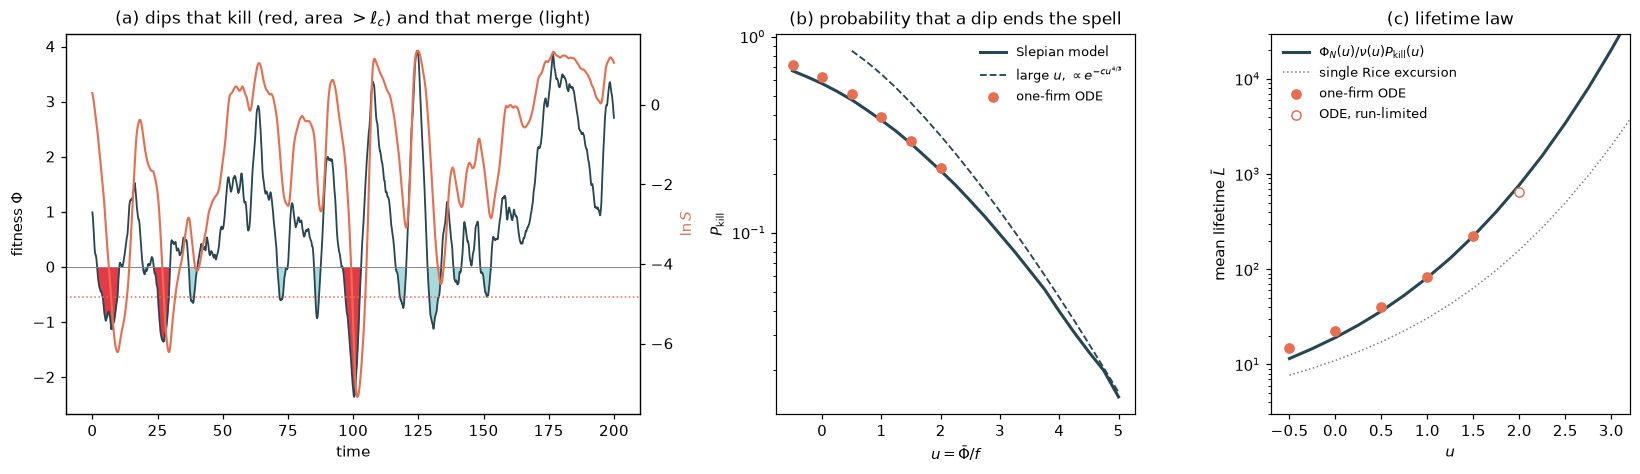

In [7]:
def pkill_slepian(u, f=F, tau=TAU, n=20000, tmax=12.0, dt=0.05, seed=0):
    rng = np.random.default_rng(seed)
    t = dt * np.arange(1, int(tmax * tau / dt) + 1)
    rho = lambda L: (1 + np.abs(L) / tau) * np.exp(-np.abs(L) / tau)
    drho = lambda L: -(L / tau ** 2) * np.exp(-np.abs(L) / tau)
    Cov = rho(t[:, None] - t[None, :]) - np.outer(rho(t), rho(t)) - tau ** 2 * np.outer(drho(t), drho(t))
    Lc = np.linalg.cholesky(Cov + 1e-9 * np.eye(t.size))
    sdot = np.sqrt(-2 * np.log(rng.random(n))) / tau            # Rayleigh crossing slopes
    eta = -u * rho(t)[None, :] + tau ** 2 * sdot[:, None] * drho(t)[None, :] + rng.standard_normal((n, t.size)) @ Lc.T
    ph = f * (u + eta)
    ret = np.argmax(ph >= 0, axis=1)
    never = ~(ph >= 0).any(1)
    inside = np.arange(t.size)[None, :] < np.where(never, t.size, ret)[:, None]
    area = -(np.minimum(ph, 0) * inside).sum(1) * dt
    return np.mean(never | (area > lc(f * sdot)))


def pkill_asymptotic(u, f=F, tau=TAU):
    sd = brentq(lambda sd: (2 / 3) * f * sd ** 3 * tau ** 4 / u ** 2 - lc(f * sd), 1e-3 / tau, 50 / tau)
    return np.exp(-(sd * tau) ** 2 / 2)


u_th = np.linspace(-0.5, 5.0, 23)
pk_sl = np.array(Parallel(n_jobs=6)(delayed(pkill_slepian)(u) for u in u_th))
u_as = u_th[u_th > 0.4]
nu = lambda u: np.exp(-u ** 2 / 2) / (2 * np.pi * TAU)
pk_ode = np.array([r[0][:, 2].mean() for r in R])
L_ode = np.array([r[1].mean() for r in R])
T_ode = np.array([r[2] for r in R])
print("    u   P_kill ODE  Slepian   mean lifetime ODE   law (no simulation)")
for u, a, b, c in zip(us, pk_ode, np.interp(us, u_th, pk_sl), L_ode):
    print(f"{u:5.1f}   {a:.3f}      {b:.3f}     {c:8.1f}            {norm.cdf(u) / (nu(u) * b):8.1f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
P, X = simulate(np.array([0.5 * F]), F, TAU, LAM, 3, 210.0)
t = DTI * np.arange(P.shape[1])
sel = t < 200
p, x, t = P[0, sel], X[0, sel], t[sel]
a = ax[0]
a.plot(t, p, color="#264653", lw=1.2)
d = np.diff((p < 0).astype(int))
st, en = np.where(d == 1)[0] + 1, np.where(d == -1)[0] + 1
if en.size and st.size and en[0] < st[0]:
    en = en[1:]
for s0, e0 in zip(st, en):
    s, area = (p[s0 - 1] - p[s0 + 1]) / (2 * DTI), -p[s0:e0].sum() * DTI
    a.fill_between(t[s0:e0], p[s0:e0], 0, color="#e63946" if area > lc(s) else "#a8dadc", lw=0)
a.axhline(0, color="grey", lw=0.6)
b2 = a.twinx()
b2.plot(t, np.log(x), color="#e76f51", lw=1.4)
b2.axhline(np.log(THR), color="#e76f51", ls=":", lw=1)
b2.set_ylabel(r"$\ln S$", color="#e76f51")
a.set(xlabel="time", ylabel=r"fitness $\Phi$", title=r"(a) dips that kill (red, area $>\ell_c$) and that merge (light)")
a = ax[1]
a.plot(u_th, pk_sl, color="#264653", lw=2, label="Slepian model")
a.plot(u_as, [pkill_asymptotic(u) for u in u_as], color="#264653", ls="--", lw=1.2, label=r"large $u$, $\propto e^{-cu^{4/3}}$")
a.scatter(us, pk_ode, color="#e76f51", zorder=5, label="one-firm ODE")
a.set(yscale="log", xlabel=r"$u=\bar\Phi/f$", ylabel=r"$P_{\rm kill}$", title="(b) probability that a dip ends the spell")
a.legend(fontsize=8.5, frameon=False)
a = ax[2]
a.plot(u_th, norm.cdf(u_th) / (nu(u_th) * pk_sl), color="#264653", lw=2, label=r"$\Phi_N(u)/\nu(u)P_{\rm kill}(u)$")
a.plot(u_th, norm.cdf(u_th) / nu(u_th), color="grey", lw=1, ls=":", label="single Rice excursion")
ok = L_ode < 0.1 * T_ode
a.scatter(us[ok], L_ode[ok], color="#e76f51", zorder=5, label="one-firm ODE")
a.scatter(us[~ok], L_ode[~ok], facecolor="white", edgecolor="#e76f51", zorder=5, label="ODE, run-limited")
a.set(yscale="log", xlim=(-0.7, 3.2), ylim=(3, 3e4), xlabel="$u$", ylabel=r"mean lifetime $\bar L$", title="(c) lifetime law")
a.legend(fontsize=8.5, frameon=False)
plt.tight_layout()

With no simulation input the law gives the mean lifetime to a few per cent for $u\ge1$ and runs 10–20% low for
$u\le0.5$, where short spells and the entry and exit delays matter. Two consequences:

1. **Lifetime grows faster than any power of size.** With $\bar S\simeq uf$, $\ln\bar L$ grows as $\bar S^2/2f^2$: the decline
   branch steepens with size, and the spell $\beta$ is an effective exponent that depends on the fitted size range.
2. **Slow convergence.** Firms that outlive the window appear as one cut-off spell; the crossover is at
   $\bar L(u_\times)\simeq T$, so $u_\times$ grows only as $\sqrt{2\ln T}$.

## Why the deterministic limit is not enough

The full model under the spell panel ($T=480$, eight economies, fixed-range estimator on the larger half of spells):

| | $\beta$ | $\zeta_q/\zeta_1$ |
|---|---|---|
| $\alpha=6$, $\sigma=1.75$ | $0.55\pm0.03$ | 1.84, 2.50, 3.00 |
| $\alpha=3.5$, $\sigma=1.9$ | $0.28\pm0.03$ | 1.79, 2.30, 2.53 |
| $\alpha=2.5$, $\sigma=1.75$ | $0.19$ | 1.42, 1.34, 0.95 |
| Compustat | 0.20 | 2.0, 2.6, 2.9 |

The ratio curve is robust and, on light tails, close to the data: its bend is the life-cycle mechanism above. But no
point gives $\beta\approx0.2$ together with data-like ratios: light tails give data-like ratios with $\beta=0.55$; heavy
tails give $\beta\approx0.2$ with a flat or falling ratio curve, because the spread of fitness amplitudes $f\propto\sqrt\kappa$
adds lifetime dispersion at fixed size (shuffling $f$ across firms keeps the curve flat; making $f$ homogeneous restores
the plain life-cycle bend). And the volatility is dominated by entry and exit through an arbitrary listing threshold
$S_{\rm thr}\approx10^{-2}$ of the mean.

Replacing the floor by birth–death noise with turnover (notebook 04) removes the threshold — a firm enters at $D$ and exits at
zero — and gives small firms a size-dependent noise of their own.